# 3.4.2 Temperature-swing cycles on the Marx T15 system

Reads the runs written by `generate.py` and executed by `run.py`: two-step TSA cycles (adsorption with feed
and surroundings at 298 K, regeneration at 373 K, equal step durations $t_{1/2}$) on the validated T15 column
with the energy balance on, and the equilibrium loadings of the feed (the mixture method of the input, SCI) at both temperatures.

Per-cycle quantities are taken from the CO$_2$ inventory of the column per unit cross-section,
$n(t) = \sum_{i=1}^{N_z} \Delta z\,[\varepsilon_b c_i + (1-\varepsilon_b)\rho_s q_i]$ (nodes $i \geq 1$; node 0 is the
fixed inlet node), divided by the adsorbent mass per unit cross-section, $(1-\varepsilon_b)\rho_s L$:

- uptake during the adsorption step and release during the regeneration step of cycle $k$;
- cyclic-steady-state residual $r_k = |\text{uptake}_k - \text{release}_k| / \text{release}_k$, the CO$_2$ that
  accumulates per cycle relative to the working capacity;
- working capacity $\Delta q_{\mathrm{cyc}}$ = release of the last complete cycle; productivity
  $\dot{q}_{\mathrm{cyc}} = \Delta q_{\mathrm{cyc}}/(2t_{1/2})$.

The paper panels are written to `ruptura-2.0-paper/figures/cycles/`.

In [1]:
import json
import re
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "simulations" / "index.json").is_file():
    raise FileNotFoundError("Run this notebook from validation/3.4.2_swing_adsorption after generate.py and run.py.")
REPOSITORY = ROOT.parent.parent
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "cycles"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SHOWN_HALF_CYCLE = 4000  # s, the run shown in panels (a) and (b)

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
@lru_cache(maxsize=None)
def data_column_index(path_string, heading):
    """Resolve a one-based Ruptura '# column N:' header to a NumPy index (as in marx2/create.ipynb)."""
    prefix = heading.casefold()
    with Path(path_string).open("rt", encoding="utf-8") as handle:
        for line in handle:
            if not line.startswith("#"):
                break
            if line.startswith("# column "):
                number_text, description = line[9:].split(":", 1)
                if description.strip().casefold().startswith(prefix):
                    return int(number_text) - 1
    raise ValueError(f"Column heading {heading!r} not found in {path_string}")


@lru_cache(maxsize=None)
def load_fields(directory):
    """Full CO2 and column fields of one run, as arrays of shape (output blocks, grid nodes)."""
    directory = ROOT / directory
    simulation = json.loads((directory / "simulation.json").read_text())
    nodes = simulation["NumberOfGridPoints"] + 1
    fields = {"simulation": simulation}

    path = str(directory / "component_1_CO2.data")
    headings = ("Time, t", "Column position", "Concentration, c_i", "Mole fraction", "Physisorption, q_phy")
    columns = [data_column_index(path, heading) for heading in headings]
    data = pd.read_csv(path, sep=r"\s+", comment="#", header=None, usecols=columns)[[*columns]].to_numpy()
    blocks = len(data) // nodes
    data = data[: blocks * nodes].reshape(blocks, nodes, len(columns))
    fields["time"] = 60.0 * data[:, 0, 0]
    fields["z"] = data[0, :, 1]
    fields["c"], fields["y"], fields["q"] = data[:, :, 2], data[:, :, 3], data[:, :, 4]

    path = str(directory / "column.data")
    headings = ("Interstitial gas velocity", "Gas temperature,", "Solid temperature,", "Wall temperature,")
    columns = [data_column_index(path, heading) for heading in headings]
    data = pd.read_csv(path, sep=r"\s+", comment="#", header=None, usecols=columns)[[*columns]].to_numpy()
    data = data[: blocks * nodes].reshape(blocks, nodes, len(columns))
    fields["v"], fields["Tg"], fields["Ts"], fields["Tw"] = (data[:, :, i] for i in range(4))
    return fields


def co2_inventory(fields):
    """CO2 in the column per unit cross-section [mol/m2] and adsorbent mass per unit cross-section [kg/m2]."""
    simulation = fields["simulation"]
    void, density = simulation["ColumnVoidFraction"], simulation["ParticleDensity"]
    spacing = fields["z"][1] - fields["z"][0]
    inventory = spacing * (void * fields["c"][:, 1:] + (1.0 - void) * density * fields["q"][:, 1:]).sum(axis=1)
    return inventory, (1.0 - void) * density * simulation["ColumnLength"]


def cycle_table(directory, half_cycle):
    """Uptake and release per complete cycle [mol/kg], and the bed-averaged solid temperature at the step ends."""
    fields = load_fields(directory)
    inventory, adsorbent = co2_inventory(fields)
    output_interval = fields["time"][1] - fields["time"][0]
    boundaries = []
    for k in range(int(round(fields["time"][-1] / half_cycle)) + 2):
        index = int(np.argmin(np.abs(fields["time"] - k * half_cycle)))
        if abs(fields["time"][index] - k * half_cycle) < 0.5 * output_interval:
            boundaries.append(index)
    rows = []
    for k in range((len(boundaries) - 1) // 2):
        start, switch, end = boundaries[2 * k], boundaries[2 * k + 1], boundaries[2 * k + 2]
        uptake = (inventory[switch] - inventory[start]) / adsorbent
        release = (inventory[switch] - inventory[end]) / adsorbent
        rows.append({
            "cycle": k + 1,
            "uptake_mol_per_kg": uptake,
            "release_mol_per_kg": release,
            "css_measure": abs(uptake - release) / release,
            "solid_temperature_end_adsorption_K": fields["Ts"][switch, 1:].mean(),
            "solid_temperature_end_regeneration_K": fields["Ts"][end, 1:].mean(),
        })
    return pd.DataFrame(rows)


def co2_mass_balance(directory):
    """Fed, eluted, and accumulated CO2 over the whole run [mol/m2] and the relative closure error."""
    fields = load_fields(directory)
    simulation = fields["simulation"]
    void = simulation["ColumnVoidFraction"]
    spacing = fields["z"][1] - fields["z"][0]
    dispersion = next(c for c in simulation["Components"] if c["Name"] == "CO2")["AxialDispersionCoefficient"]
    inventory, _ = co2_inventory(fields)
    # With the Danckwerts inlet (the default) exactly the feed v c_0 enters; with a Dirichlet inlet, dispersion
    # across the inlet face adds to it.
    inflow = void * fields["v"][:, 0] * fields["c"][:, 0]
    if simulation.get("InletCondition", "Danckwerts") == "Dirichlet":
        inflow = inflow - void * dispersion * (fields["c"][:, 1] - fields["c"][:, 0]) / spacing
    outflow = void * fields["v"][:, -1] * fields["c"][:, -1]
    fed = np.trapezoid(inflow, fields["time"])
    eluted = np.trapezoid(outflow, fields["time"])
    accumulated = inventory[-1] - inventory[0]
    return {"fed": fed, "eluted": eluted, "accumulated": accumulated, "closure": (fed - eluted - accumulated) / fed}


def equilibrium_loading(directory):
    """Equilibrium (SCI) CO2 loading of the feed [mol/kg] from a MixturePrediction run."""
    path = ROOT / directory / "component_0_CO2.data"
    return float(np.loadtxt(path, comments="#", ndmin=2)[0, data_column_index(str(path), "mixture component")])


def wall_time(directory):
    match = re.findall(r"Total time:\s+([0-9.eE+-]+) s", (ROOT / directory / "run.log").read_text())
    return float(match[-1])

In [3]:
INDEX = pd.DataFrame(json.loads((ROOT / "simulations" / "index.json").read_text()))
EQUILIBRIUM = {
    row.temperature_K: equilibrium_loading(row.directory) for row in INDEX[INDEX["kind"] == "equilibrium"].itertuples()
}
EQUILIBRIUM_CAPACITY = EQUILIBRIUM[298.0] - EQUILIBRIUM[373.0]

rows = []
CYCLES = {}
for run in INDEX[INDEX["kind"] == "cycle"].itertuples():
    half_cycle = int(run.half_cycle_s)
    table = cycle_table(run.directory, half_cycle)
    CYCLES[half_cycle] = table
    last = table.iloc[-1]
    balance = co2_mass_balance(run.directory)
    rows.append({
        "half_cycle_s": half_cycle,
        "complete_cycles": len(table),
        "working_capacity_mol_per_kg": last["release_mol_per_kg"],
        "fraction_of_equilibrium": last["release_mol_per_kg"] / EQUILIBRIUM_CAPACITY,
        "productivity_mol_per_kg_s": last["release_mol_per_kg"] / (2.0 * half_cycle),
        "css_measure_last_cycle": last["css_measure"],
        "solid_temperature_swing_K": last["solid_temperature_end_regeneration_K"] - last["solid_temperature_end_adsorption_K"],
        "mass_balance_closure": balance["closure"],
        "wall_time_s": wall_time(run.directory),
        "wall_time_per_cycle_s": wall_time(run.directory) / run.number_of_cycles,
    })
SUMMARY = pd.DataFrame(rows).set_index("half_cycle_s")

print(f"SCI CO2 loading: {EQUILIBRIUM[298.0]:.4f} mol/kg at 298 K, {EQUILIBRIUM[373.0]:.4f} mol/kg at 373 K")
print(f"Equilibrium working capacity: {EQUILIBRIUM_CAPACITY:.4f} mol/kg")
SUMMARY

SCI CO2 loading: 3.3639 mol/kg at 298 K, 1.0492 mol/kg at 373 K
Equilibrium working capacity: 2.3147 mol/kg


,complete_cycles,working_capacity_mol_per_kg,fraction_of_equilibrium,productivity_mol_per_kg_s,css_measure_last_cycle,solid_temperature_swing_K,mass_balance_closure,wall_time_s,wall_time_per_cycle_s
half_cycle_s,,,,,,,,,
1000,30,0.214473,0.092658,0.000107,5.725360e-07,7.400615,0.000276,60.943055,2.031435
2000,15,0.489077,0.211294,0.000122,5.303144e-07,14.851508,0.000303,57.152942,3.810196
4000,8,0.980795,0.423730,0.000123,3.873306e-07,28.848733,0.000314,55.734101,6.966763
8000,5,1.654745,0.714895,0.000103,2.474485e-07,50.742815,0.000278,61.356754,12.271351
16000,5,2.217450,0.957999,0.000069,2.297019e-07,70.094555,0.000148,84.221287,16.844257


## (a) Bed-averaged CO$_2$ loading

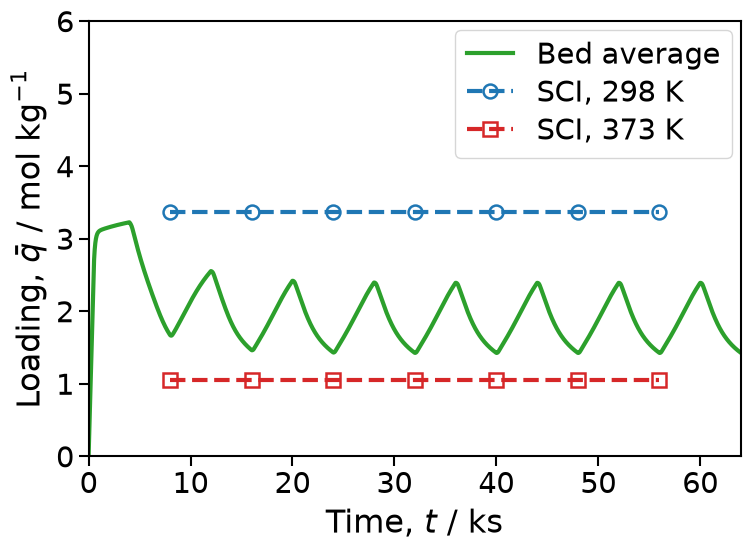

In [4]:
run = INDEX[(INDEX["kind"] == "cycle") & (INDEX["half_cycle_s"] == SHOWN_HALF_CYCLE)].iloc[0]
fields = load_fields(run.directory)
mean_loading = fields["q"][:, 1:].mean(axis=1)
equilibrium_times = np.linspace(0.0, fields["time"][-1], 9)[1:-1]

fig, ax = plt.subplots()
ax.plot(fields["time"] / 1000.0, mean_loading, color="C2", linestyle="-", label="Bed average")
ax.plot(equilibrium_times / 1000.0, [EQUILIBRIUM[298.0]] * len(equilibrium_times), color="C0", linestyle="--", marker="o",
        markerfacecolor="none", label="SCI, 298 K")
ax.plot(equilibrium_times / 1000.0, [EQUILIBRIUM[373.0]] * len(equilibrium_times), color="C3", linestyle="--", marker="s",
        markerfacecolor="none", label="SCI, 373 K")
ax.set_xlim(0.0, fields["time"][-1] / 1000.0)
ax.set_ylim(0.0, 6.0)
ax.set_xlabel(r"Time, $t$ / ks")
ax.set_ylabel(r"Loading, $\bar{q}$ / mol kg$^{-1}$")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cycles_loading.pdf", dpi=300)
plt.show()

## (b) Temperatures

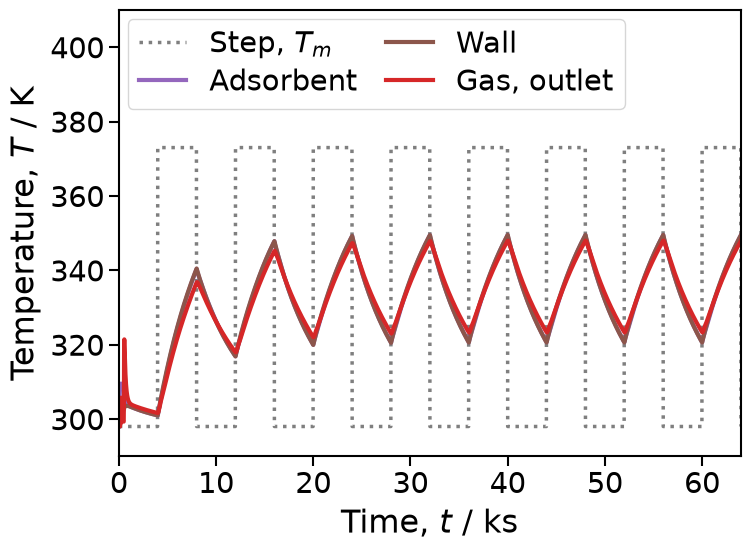

In [5]:
run = INDEX[(INDEX["kind"] == "cycle") & (INDEX["half_cycle_s"] == SHOWN_HALF_CYCLE)].iloc[0]
fields = load_fields(run.directory)
phase_temperature = np.where((fields["time"] // SHOWN_HALF_CYCLE) % 2 == 0, 298.0, 373.0)

fig, ax = plt.subplots()
ax.plot(fields["time"] / 1000.0, phase_temperature, color="C7", linestyle=":", linewidth=2.5, label=r"Step, $T_m$")
ax.plot(fields["time"] / 1000.0, fields["Ts"][:, 1:].mean(axis=1), color="C4", linestyle="-", label="Adsorbent")
ax.plot(fields["time"] / 1000.0, fields["Tw"][:, 1:].mean(axis=1), color="C5", linestyle="-", label="Wall")
ax.plot(fields["time"] / 1000.0, fields["Tg"][:, -1], color="C3", linestyle="-", label="Gas, outlet")
ax.set_xlim(0.0, fields["time"][-1] / 1000.0)
ax.set_ylim(290.0, 410.0)
ax.set_xlabel(r"Time, $t$ / ks")
ax.set_ylabel(r"Temperature, $T$ / K")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cycles_temperature.pdf", dpi=300)
plt.show()

## (c) Approach to cyclic steady state

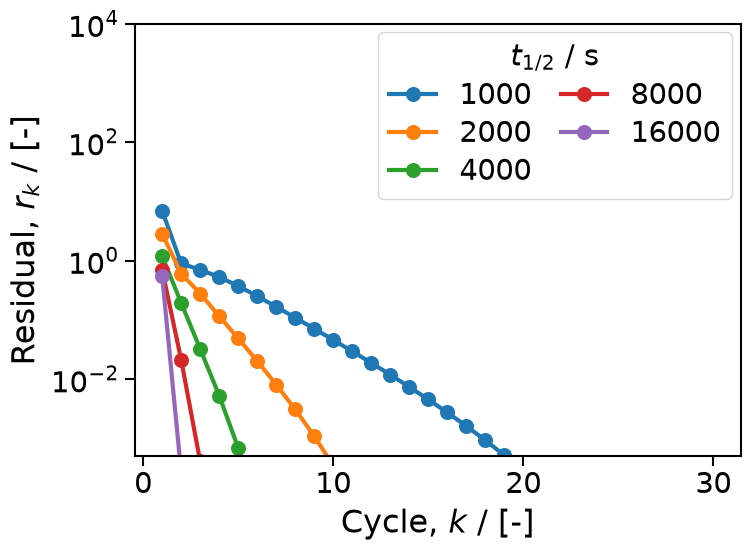

In [6]:
fig, ax = plt.subplots()
for color, (half_cycle, table) in zip(("C0", "C1", "C2", "C3", "C4"), sorted(CYCLES.items())):
    ax.plot(table["cycle"], table["css_measure"], color=color, linestyle="-", marker="o", markersize=9,
            label=f"{half_cycle}")
ax.set_yscale("log")
ax.set_ylim(5.0e-4, 1.0e4)
ax.set_xlabel(r"Cycle, $k$ / [-]")
ax.set_ylabel(r"Residual, $r_k$ / [-]")
ax.legend(loc="upper right", ncol=2, title=r"$t_{1/2}$ / s")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cycles_convergence.pdf", dpi=300)
plt.show()

## (d) Working capacity and productivity at cyclic steady state

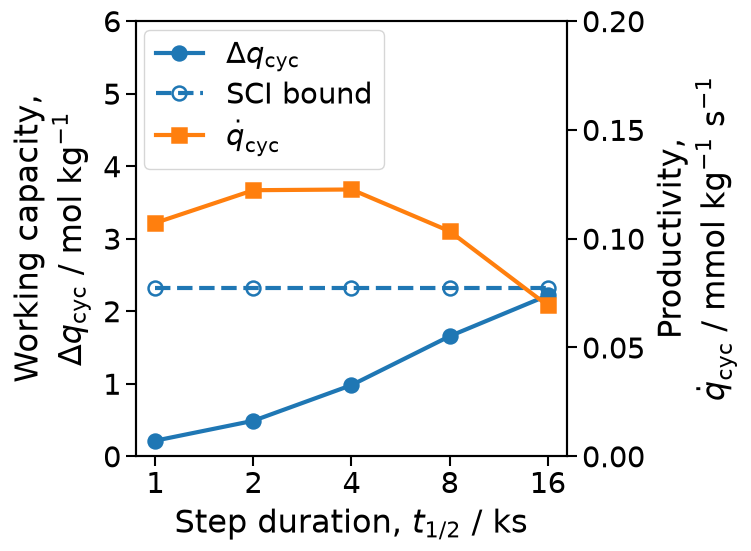

In [7]:
half_cycles = SUMMARY.index.to_numpy(dtype=float)

fig, ax = plt.subplots()
ax.plot(half_cycles, SUMMARY["working_capacity_mol_per_kg"], color="C0", linestyle="-", marker="o",
        label=r"$\Delta q_{\mathrm{cyc}}$")
ax.plot(half_cycles, [EQUILIBRIUM_CAPACITY] * len(half_cycles), color="C0", linestyle="--", marker="o",
        markerfacecolor="none", label="SCI bound")
ax.set_xscale("log")
ax.set_xticks(half_cycles, [f"{value / 1000.0:.0f}" for value in half_cycles])
ax.minorticks_off()
ax.set_ylim(0.0, 6.0)
ax.set_xlabel(r"Step duration, $t_{1/2}$ / ks")
ax.set_ylabel("Working capacity,\n" + r"$\Delta q_{\mathrm{cyc}}$ / mol kg$^{-1}$")

# Productivity in mmol kg-1 s-1, so that the ticks stay plain decimals.
twin = ax.twinx()
twin.plot(half_cycles, 1.0e3 * SUMMARY["productivity_mol_per_kg_s"], color="C1", linestyle="-", marker="s",
          label=r"$\dot{q}_{\mathrm{cyc}}$")
twin.set_ylim(0.0, 0.20)
twin.set_yticks([0.0, 0.05, 0.10, 0.15, 0.20])
twin.set_ylabel("Productivity,\n" + r"$\dot{q}_{\mathrm{cyc}}$ / mmol kg$^{-1}$ s$^{-1}$")

handles = ax.get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
labels = ax.get_legend_handles_labels()[1] + twin.get_legend_handles_labels()[1]
ax.legend(handles, labels, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cycles_performance.pdf", dpi=300)
plt.show()

## Numbers quoted in the paper

In [8]:
for half_cycle, table in sorted(CYCLES.items()):
    below = table[table["css_measure"] < 1.0e-2]
    first = int(below["cycle"].iloc[0]) if len(below) else None
    print(f"t_half = {half_cycle:5d} s: first cycle with measure < 1e-2: {first}")
print(SUMMARY.to_string(float_format=lambda value: f"{value:.4g}"))

t_half =  1000 s: first cycle with measure < 1e-2: 14
t_half =  2000 s: first cycle with measure < 1e-2: 7
t_half =  4000 s: first cycle with measure < 1e-2: 4
t_half =  8000 s: first cycle with measure < 1e-2: 3
t_half = 16000 s: first cycle with measure < 1e-2: 2
              complete_cycles  working_capacity_mol_per_kg  fraction_of_equilibrium  productivity_mol_per_kg_s  css_measure_last_cycle  solid_temperature_swing_K  mass_balance_closure  wall_time_s  wall_time_per_cycle_s
half_cycle_s                                                                                                                                                                                                               
1000                       30                       0.2145                  0.09266                  0.0001072               5.725e-07                      7.401             0.0002756        60.94                  2.031
2000                       15                       0.4891                